### Importing libraries

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)

### Create a Small Sentiment Dataset

In [5]:
texts = [
    "this movie was amazing",
    "i loved this film",
    "the acting was fantastic",
    "what a wonderful story",
    "this film was great",
    "i really enjoyed the movie",
    "the performance was excellent",
    "this was a beautiful experience",

    "this movie was terrible",
    "i hated this film",
    "the acting was boring",
    "what a bad story",
    "this film was awful",
    "i really disliked the movie",
    "the performance was poor",
    "this was a disappointing experience"
]

labels = [
    1, 1, 1, 1, 1, 1, 1, 1,
    0, 0, 0, 0, 0, 0, 0, 0
]

print("Number of samples:", len(texts))

Number of samples: 16


### Simple Tokenization

In [10]:
def tokenize(text):
    return text.lower().split()

tokenized_texts = [tokenize(text) for text in texts]

for text, tokens in zip(texts[:3], tokenized_texts[:3]):
    print(text, "->", tokens)

this movie was amazing -> ['this', 'movie', 'was', 'amazing']
i loved this film -> ['i', 'loved', 'this', 'film']
the acting was fantastic -> ['the', 'acting', 'was', 'fantastic']


### Building Vocabulary

In [13]:
special_tokens = ["<PAD>", "<UNK>"]

vocab = {}

for token in special_tokens:
    vocab[token] = len(vocab)

for tokens in tokenized_texts:
    for token in tokens:
        if token not in vocab:
            vocab[token] = len(vocab)

id_to_word = {idx: word for word, idx in vocab.items()}

print("Vocabulary size:", len(vocab))
print(vocab)

Vocabulary size: 31
{'<PAD>': 0, '<UNK>': 1, 'this': 2, 'movie': 3, 'was': 4, 'amazing': 5, 'i': 6, 'loved': 7, 'film': 8, 'the': 9, 'acting': 10, 'fantastic': 11, 'what': 12, 'a': 13, 'wonderful': 14, 'story': 15, 'great': 16, 'really': 17, 'enjoyed': 18, 'performance': 19, 'excellent': 20, 'beautiful': 21, 'experience': 22, 'terrible': 23, 'hated': 24, 'boring': 25, 'bad': 26, 'awful': 27, 'disliked': 28, 'poor': 29, 'disappointing': 30}


### Convert Text to Token IDs

In [16]:
def numericalize(tokens, vocab):
    return [vocab.get(token, vocab["<UNK>"]) for token in tokens]

encoded_texts = [numericalize(tokens, vocab) for tokens in tokenized_texts]

for text, encoded in zip(texts[:5], encoded_texts[:5]):
    print(text)
    print(encoded)
    print()

this movie was amazing
[2, 3, 4, 5]

i loved this film
[6, 7, 2, 8]

the acting was fantastic
[9, 10, 4, 11]

what a wonderful story
[12, 13, 14, 15]

this film was great
[2, 8, 4, 16]



### Padding Sentences

In [19]:
max_len = 6
pad_id = vocab["<PAD>"]

def pad_sequence(seq, max_len, pad_id):
    if len(seq) > max_len:
        return seq[:max_len]
    return seq + [pad_id] * (max_len - len(seq))

padded_texts = [pad_sequence(seq, max_len, pad_id) for seq in encoded_texts]

for text, padded in zip(texts[:5], padded_texts[:5]):
    print(text)
    print(padded)
    print()

this movie was amazing
[2, 3, 4, 5, 0, 0]

i loved this film
[6, 7, 2, 8, 0, 0]

the acting was fantastic
[9, 10, 4, 11, 0, 0]

what a wonderful story
[12, 13, 14, 15, 0, 0]

this film was great
[2, 8, 4, 16, 0, 0]



### Create Attention Mask

In [22]:
attention_masks = []

for seq in padded_texts:
    mask = [1 if token_id != pad_id else 0 for token_id in seq]
    attention_masks.append(mask)

for padded, mask in zip(padded_texts[:5], attention_masks[:5]):
    print("Token IDs:", padded)
    print("Mask:     ", mask)
    print()

Token IDs: [2, 3, 4, 5, 0, 0]
Mask:      [1, 1, 1, 1, 0, 0]

Token IDs: [6, 7, 2, 8, 0, 0]
Mask:      [1, 1, 1, 1, 0, 0]

Token IDs: [9, 10, 4, 11, 0, 0]
Mask:      [1, 1, 1, 1, 0, 0]

Token IDs: [12, 13, 14, 15, 0, 0]
Mask:      [1, 1, 1, 1, 0, 0]

Token IDs: [2, 8, 4, 16, 0, 0]
Mask:      [1, 1, 1, 1, 0, 0]



### Create PyTorch Dataset

In [26]:
class SentimentDataset(Dataset):
    def __init__(self, input_ids, attention_masks, labels):
        self.input_ids = torch.tensor(input_ids, dtype=torch.long)
        self.attention_masks = torch.tensor(attention_masks, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)
        
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_masks[idx],
            "label": self.labels[idx]
        }

dataset = SentimentDataset(padded_texts, attention_masks, labels)

sample = dataset[0]

print(sample)

{'input_ids': tensor([2, 3, 4, 5, 0, 0]), 'attention_mask': tensor([1, 1, 1, 1, 0, 0]), 'label': tensor(1)}


In [29]:
batch_size = 4

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

batch = next(iter(dataloader))

print("input_ids shape:     ", batch["input_ids"].shape)
print("attention_mask shape:", batch["attention_mask"].shape)
print("label shape:         ", batch["label"].shape)

input_ids shape:      torch.Size([4, 6])
attention_mask shape: torch.Size([4, 6])
label shape:          torch.Size([4])


### Tranformer Encoder Block

In [32]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        
    def forward(self, x, attention_mask=None):
        B, T, d_model = x.shape
        
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)
        
        Q = Q.view(B, T, self.num_heads, self.d_head).transpose(1, 2)
        K = K.view(B, T, self.num_heads, self.d_head).transpose(1, 2)
        V = V.view(B, T, self.num_heads, self.d_head).transpose(1, 2)
        
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.d_head ** 0.5)
        
        if attention_mask is not None:
            # attention_mask shape: (B, T)
            # converted to: (B, 1, 1, T)
            mask = attention_mask[:, None, None, :]
            scores = scores.masked_fill(mask == 0, float("-inf"))
        
        attention_weights = F.softmax(scores, dim=-1)
        
        context = torch.matmul(attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(B, T, d_model)
        
        out = self.W_o(context)
        
        return out, attention_weights

In [34]:
class AddNorm(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        
    def forward(self, x, sublayer_output):
        return self.norm(x + sublayer_output)


class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )
        
    def forward(self, x):
        return self.net(x)

In [36]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()
        
        self.mha = MultiHeadSelfAttention(d_model, num_heads)
        self.add_norm1 = AddNorm(d_model)
        self.ffn = PositionWiseFeedForward(d_model, d_ff)
        self.add_norm2 = AddNorm(d_model)
        
    def forward(self, x, attention_mask=None):
        attention_output, attention_weights = self.mha(x, attention_mask)
        x = self.add_norm1(x, attention_output)
        
        ffn_output = self.ffn(x)
        x = self.add_norm2(x, ffn_output)
        
        return x, attention_weights

### Add Token Embedding and Positional Embedding

In [39]:
class SingleBlockTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, d_ff, max_len, num_classes):
        super().__init__()
        
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.position_embedding = nn.Embedding(max_len, d_model)
        
        self.encoder = TransformerEncoderBlock(d_model, num_heads, d_ff)
        
        self.classifier = nn.Linear(d_model, num_classes)
        
    def forward(self, input_ids, attention_mask=None):
        B, T = input_ids.shape
        
        positions = torch.arange(T, device=input_ids.device).unsqueeze(0).expand(B, T)
        
        token_emb = self.token_embedding(input_ids)
        pos_emb = self.position_embedding(positions)
        
        x = token_emb + pos_emb
        
        encoder_output, attention_weights = self.encoder(x, attention_mask)
        
        # Mean pooling over non-padding tokens
        if attention_mask is not None:
            mask = attention_mask.unsqueeze(-1)
            masked_output = encoder_output * mask
            pooled = masked_output.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        else:
            pooled = encoder_output.mean(dim=1)
        
        logits = self.classifier(pooled)
        
        return logits, attention_weights

### Test Forward Pass

In [42]:
vocab_size = len(vocab)
d_model = 32
num_heads = 4
d_ff = 64
num_classes = 2

single_model = SingleBlockTransformerClassifier(
    vocab_size=vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    d_ff=d_ff,
    max_len=max_len,
    num_classes=num_classes
)

batch = next(iter(dataloader))

logits, attention_weights = single_model(
    batch["input_ids"],
    batch["attention_mask"]
)

print("Input IDs shape:       ", batch["input_ids"].shape)
print("Logits shape:          ", logits.shape)
print("Attention weights shape:", attention_weights.shape)

Input IDs shape:        torch.Size([4, 6])
Logits shape:           torch.Size([4, 2])
Attention weights shape: torch.Size([4, 4, 6, 6])


### Training the Single-Block Transformer Classifier

In [44]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(single_model.parameters(), lr=0.005)

num_epochs = 40

In [47]:
single_model.train()

for epoch in range(num_epochs):
    total_loss = 0
    
    for batch in dataloader:
        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]
        labels_batch = batch["label"]
        
        logits, _ = single_model(input_ids, attention_mask)
        
        loss = criterion(logits, labels_batch)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(dataloader)
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1:02d} | Loss: {avg_loss:.4f}")

Epoch 05 | Loss: 0.5575
Epoch 10 | Loss: 0.0148
Epoch 15 | Loss: 0.0009
Epoch 20 | Loss: 0.0005
Epoch 25 | Loss: 0.0005
Epoch 30 | Loss: 0.0004
Epoch 35 | Loss: 0.0004
Epoch 40 | Loss: 0.0003


### Evaluate on Training Examples

In [50]:
def predict_sentiment(model, text, vocab, max_len):
    model.eval()
    
    tokens = tokenize(text)
    ids = numericalize(tokens, vocab)
    padded = pad_sequence(ids, max_len, vocab["<PAD>"])
    mask = [1 if token_id != vocab["<PAD>"] else 0 for token_id in padded]
    
    input_ids = torch.tensor([padded], dtype=torch.long)
    attention_mask = torch.tensor([mask], dtype=torch.long)
    
    with torch.no_grad():
        logits, attention_weights = model(input_ids, attention_mask)
        probs = F.softmax(logits, dim=-1)
        pred = torch.argmax(probs, dim=-1).item()
    
    label = "Positive" if pred == 1 else "Negative"
    
    return label, probs.squeeze(), attention_weights

In [52]:
test_sentences = [
    "this movie was amazing",
    "this movie was terrible",
    "the acting was fantastic",
    "the acting was boring"
]

for sentence in test_sentences:
    label, probs, _ = predict_sentiment(single_model, sentence, vocab, max_len)
    print(f"Text: {sentence}")
    print(f"Prediction: {label}")
    print(f"Probabilities: {probs}")
    print()

Text: this movie was amazing
Prediction: Positive
Probabilities: tensor([2.7349e-04, 9.9973e-01])

Text: this movie was terrible
Prediction: Negative
Probabilities: tensor([9.9966e-01, 3.4272e-04])

Text: the acting was fantastic
Prediction: Positive
Probabilities: tensor([3.1664e-04, 9.9968e-01])

Text: the acting was boring
Prediction: Negative
Probabilities: tensor([9.9964e-01, 3.6431e-04])



In [55]:
new_sentences = [
    "what a fantastic movie",
    "this story was awful",
    "i enjoyed this film",
    "i disliked the performance"
]

for sentence in new_sentences:
    label, probs, _ = predict_sentiment(single_model, sentence, vocab, max_len)
    print(f"Text: {sentence}")
    print(f"Prediction: {label}")
    print(f"Probabilities: {probs}")
    print()

Text: what a fantastic movie
Prediction: Positive
Probabilities: tensor([3.1684e-04, 9.9968e-01])

Text: this story was awful
Prediction: Negative
Probabilities: tensor([9.9954e-01, 4.5522e-04])

Text: i enjoyed this film
Prediction: Positive
Probabilities: tensor([3.5368e-04, 9.9965e-01])

Text: i disliked the performance
Prediction: Negative
Probabilities: tensor([0.7842, 0.2158])



### Visualize Attention for One Sentence

In [57]:
example_sentence = "this movie was amazing"

label, probs, attention_weights = predict_sentiment(
    single_model,
    example_sentence,
    vocab,
    max_len
)

tokens = tokenize(example_sentence)
ids = numericalize(tokens, vocab)
padded = pad_sequence(ids, max_len, vocab["<PAD>"])
tokens_padded = tokens + ["<PAD>"] * (max_len - len(tokens))

print("Sentence:", example_sentence)
print("Prediction:", label)
print("Tokens:", tokens_padded)
print("Attention shape:", attention_weights.shape)

Sentence: this movie was amazing
Prediction: Positive
Tokens: ['this', 'movie', 'was', 'amazing', '<PAD>', '<PAD>']
Attention shape: torch.Size([1, 4, 6, 6])


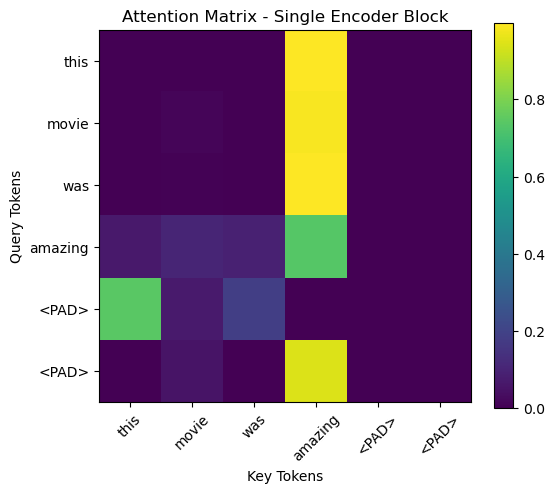

In [59]:
import matplotlib.pyplot as plt

head_id = 0
attn_matrix = attention_weights[0, head_id].detach()

plt.figure(figsize=(6, 5))
plt.imshow(attn_matrix)
plt.colorbar()
plt.xticks(range(max_len), tokens_padded, rotation=45)
plt.yticks(range(max_len), tokens_padded)
plt.title("Attention Matrix - Single Encoder Block")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.show()